# 03 · Classificadores
**Modelo 1 — “esta conversa vira pedido em 7 dias?”** (regressão logística vs. árvore de decisão/boosting).
**Modelo 2 — “este pedido vai virar reclamação ou cancelamento?”** (classe desbalanceada → precisão/recall e curva PR).

Divisão **temporal** (treino: até jun/2026; teste: depois) para simular uso real, sem vazamento do futuro.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings; warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"font.size":10})
D="../data/core/"; ped=pd.read_csv(D+"fato_pedido.csv",parse_dates=["data_pedido"]); conv=pd.read_csv(D+"fato_conversa.csv",parse_dates=["iniciada_em"])
post=pd.read_csv(D+"fato_post_instagram.csv",parse_dates=["publicado_em"]); plat=pd.read_csv(D+"dim_plataforma.csv").set_index("plataforma_id"); loja=pd.read_csv(D+"dim_loja.csv",parse_dates=["data_adocao_atria"])
ped["canal"]=ped.plataforma_id.map(plat.nome); ped["mes"]=ped.data_pedido.dt.to_period("M")
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,accuracy_score,precision_score,recall_score,f1_score,roc_curve,roc_auc_score,precision_recall_curve,average_precision_score)
CORTE=pd.Timestamp("2026-07-01")

## Modelo 1 · conversa → pedido em 7 dias
Variáveis conhecidas **no momento da primeira resposta**: intenção, canal, hora, dia da semana, recorrência, valor histórico, origem em post, mensagens do cliente e **tempo de resposta**.

In [2]:
c=conv.dropna(subset=["converteu_7d"]).copy(); c["y"]=c.converteu_7d.astype(int); c["origem_post"]=c.origem_post_id.notna().astype(int)
c["resp"]=c.tempo_primeira_resposta_min.fillna(14400); c["log_resp"]=np.log1p(c.resp)
num=["log_resp","hora","dia_semana","cliente_recorrente","valor_historico","msgs_cliente","enviou_midia","origem_post"]; cat=["intencao","canal"]
tr=c[c.iniciada_em<CORTE]; te=c[c.iniciada_em>=CORTE]; print("treino",len(tr),"teste",len(te),"| taxa de conversão treino/teste:",tr.y.mean().round(3),te.y.mean().round(3))
pre=ColumnTransformer([("n",StandardScaler(),num),("c",OneHotEncoder(handle_unknown="ignore"),cat)])
base=make_pipeline(ColumnTransformer([("c",OneHotEncoder(handle_unknown="ignore"),cat)]),LogisticRegression(max_iter=500))
lr=make_pipeline(pre,LogisticRegression(max_iter=1000)); gb=make_pipeline(pre,HistGradientBoostingClassifier(max_depth=4,learning_rate=.06,max_iter=200,random_state=0))
res={}
for nome,m in {"Só intenção+canal (baseline)":base,"Regressão logística":lr,"Gradient boosting":gb}.items():
    m.fit(tr[num+cat],tr.y); p=m.predict_proba(te[num+cat])[:,1]; res[nome]=(m,p)
tab=pd.DataFrame({n:{"AUC":roc_auc_score(te.y,p),"AP (precisão média)":average_precision_score(te.y,p)} for n,(m,p) in res.items()}).T.round(3); display(tab)

treino 36211 teste 10329 | taxa de conversão treino/teste: 0.262 0.273


,AUC,AP (precisão média)
Só intenção+canal (baseline),0.801,0.509
Regressão logística,0.855,0.662
Gradient boosting,0.860,0.670


**Leitura.** O baseline (só intenção e canal) já tem AUC 0,80, porque a intenção é muito informativa. Com tempo de resposta, recorrência e origem do post a AUC sobe para 0,855 e a precisão média de 0,51 para 0,66. O boosting (0,860) praticamente empata com a logística (0,855): sugere relações quase lineares no log-odds, então escolhemos a logística, mais simples e interpretável.

limiar (F1 no treino): 0.32
{'acuracia': 0.764, 'precisao': 0.546, 'recall': 0.806, 'f1': 0.651}


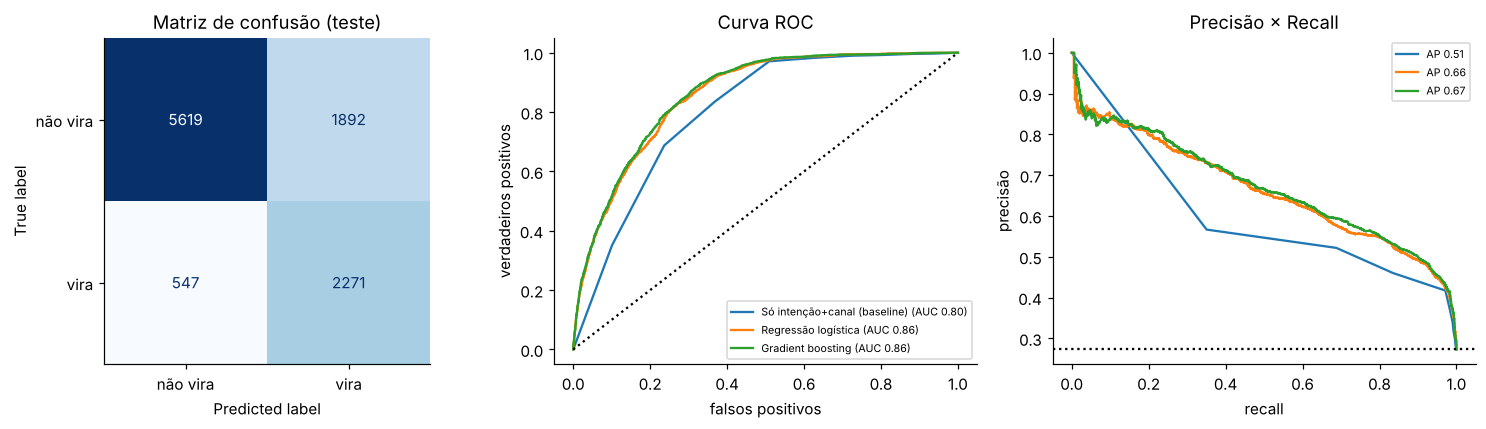

[[5619 1892]
 [ 547 2271]]


In [3]:
m,p=res["Regressão logística"]
# limiar escolhido no treino por F1
ptr=m.predict_proba(tr[num+cat])[:,1]; ths=np.linspace(.05,.8,76); f=[f1_score(tr.y,ptr>=t) for t in ths]; t=ths[int(np.argmax(f))]; yhat=(p>=t).astype(int)
print("limiar (F1 no treino):",round(t,2))
met=dict(acuracia=accuracy_score(te.y,yhat),precisao=precision_score(te.y,yhat),recall=recall_score(te.y,yhat),f1=f1_score(te.y,yhat)); print({k:round(v,3) for k,v in met.items()})
fig,ax=plt.subplots(1,3,figsize=(14,4)); ConfusionMatrixDisplay(confusion_matrix(te.y,yhat),display_labels=["não vira","vira"]).plot(ax=ax[0],colorbar=False,cmap="Blues"); ax[0].set_title("Matriz de confusão (teste)")
for n,(mm,pp) in res.items():
    fpr,tpr,_=roc_curve(te.y,pp); ax[1].plot(fpr,tpr,label=f"{n} (AUC {roc_auc_score(te.y,pp):.2f})")
    pr,rc,_=precision_recall_curve(te.y,pp); ax[2].plot(rc,pr,label=f"AP {average_precision_score(te.y,pp):.2f}")
ax[1].plot([0,1],[0,1],"k:"); ax[1].set_title("Curva ROC"); ax[1].set_xlabel("falsos positivos"); ax[1].set_ylabel("verdadeiros positivos"); ax[1].legend(fontsize=7)
ax[2].axhline(te.y.mean(),c="k",ls=":"); ax[2].set_title("Precisão × Recall"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precisão"); ax[2].legend(fontsize=7); plt.tight_layout(); plt.savefig("../out/fig/clf1.png"); plt.show()
print(confusion_matrix(te.y,yhat))

**Como ler.**
- **Acurácia** é a fração de acertos totais; com ~28% de conversões, “chutar não vira” já acerta ~72%. O modelo chega a 76%, pouco acima, então acurácia sozinha engana.
- **Precisão**: das conversas que o modelo marca como “vão virar”, quantas viram. **Recall**: das que viraram, quantas o modelo achou. **F1** equilibra os dois.
- No teste: precisão 0,55 (de cada 2 marcadas, ~1 vira) e recall 0,81 (acha 4 de cada 5 que viram), com limiar baixo escolhido no treino.
- **Uso na Atria:** priorizar a fila de mensagens abertas. Aqui, errar um falso positivo custa pouco (responder primeiro a uma conversa que não ia comprar); perder um verdadeiro positivo custa uma venda. Por isso o recall pesa mais e o limiar pode ser baixado.
- A curva ROC e a PR mostram o desempenho em todos os limiares, não só no escolhido.

,coeficiente (padronizado)
intencao_troca_devolucao,-2.11
intencao_reclamacao,-2.05
intencao_pos_venda,-1.40
canal_instagram,-1.02
canal_whatsapp,-0.66
log_resp,-0.59
dia_semana,-0.01
enviou_midia,0.00
msgs_cliente,0.01
valor_historico,0.12


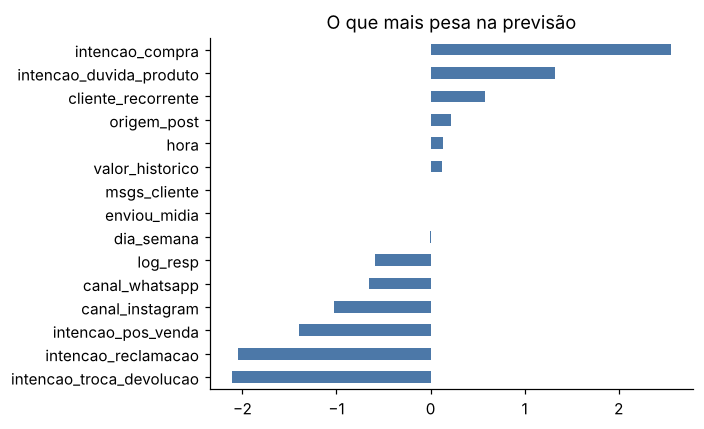

In [4]:
coefs=pd.Series(m[-1].coef_[0],index=num+list(m[0].named_transformers_["c"].get_feature_names_out(cat))).sort_values(); display(coefs.round(2).to_frame("coeficiente (padronizado)"))
fig,ax=plt.subplots(figsize=(6.5,4)); coefs.plot.barh(ax=ax,color="#4C78A8"); ax.set_title("O que mais pesa na previsão"); plt.tight_layout(); plt.savefig("../out/fig/clf1_coef.png"); plt.show()

## Modelo 2 · pedido → reclamação ou cancelamento
Classe minoritária (~7%). Variáveis conhecidas **no despacho**: categoria, canal, desconto, valor, itens, atraso no envio, evento comercial, cliente omnichannel.

In [5]:
ped2=ped.merge(pd.read_csv(D+"dim_cliente.csv")[["cliente_id","omnichannel"]],on="cliente_id",how="left")
rc=pd.read_csv(D+"fato_reclamacao.csv"); ped2["problema"]=((ped2.status=="CANCELADO")|ped2.pedido_id.isin(rc.pedido_id)).astype(int)
ped2["espera_envio_h"]=(pd.to_datetime(ped2.data_envio)-ped2.data_pedido).dt.total_seconds()/3600
# cancelados não têm envio: o atraso conhecido no momento do cancelamento vira janela de observação -> excluir (vazamento)
d=ped2[(ped2.status!="CANCELADO")].copy(); d["y"]=d.pedido_id.isin(rc.pedido_id).astype(int); d=d[d.data_pedido<pd.Timestamp("2026-10-20")]
d["espera_envio_h"]=d.espera_envio_h.fillna(d.espera_envio_h.median()); d["omni"]=d.omnichannel.astype(int); d["tem_evento"]=(d.evento.notna()).astype(int)
num2=["valor_itens","desconto_pct","qtd_itens","espera_envio_h","atrasado","omni","tem_evento"]; cat2=["categoria_principal","canal"]
tr=d[d.data_pedido<CORTE]; te=d[d.data_pedido>=CORTE]; print("taxa de reclamação treino/teste:",tr.y.mean().round(3),te.y.mean().round(3))
pre2=ColumnTransformer([("n",StandardScaler(),num2),("c",OneHotEncoder(handle_unknown="ignore"),cat2)])
mod=make_pipeline(pre2,LogisticRegression(max_iter=1000,class_weight="balanced")); mod.fit(tr[num2+cat2],tr.y); p2=mod.predict_proba(te[num2+cat2])[:,1]
gb2=make_pipeline(pre2,HistGradientBoostingClassifier(max_depth=3,learning_rate=.05,max_iter=150,random_state=0)); gb2.fit(tr[num2+cat2],tr.y); pg=gb2.predict_proba(te[num2+cat2])[:,1]
print("AUC logística",round(roc_auc_score(te.y,p2),3),"| AUC boosting",round(roc_auc_score(te.y,pg),3),"| AP logística",round(average_precision_score(te.y,p2),3),"| AP boosting",round(average_precision_score(te.y,pg),3),"| acaso (AP)",round(te.y.mean(),3))

taxa de reclamação treino/teste: 0.056 0.056
AUC logística 0.605 | AUC boosting 0.6 | AP logística 0.081 | AP boosting 0.083 | acaso (AP) 0.056


{'acuracia': 0.605, 'precisao': 0.073, 'recall': 0.525, 'f1': 0.129}


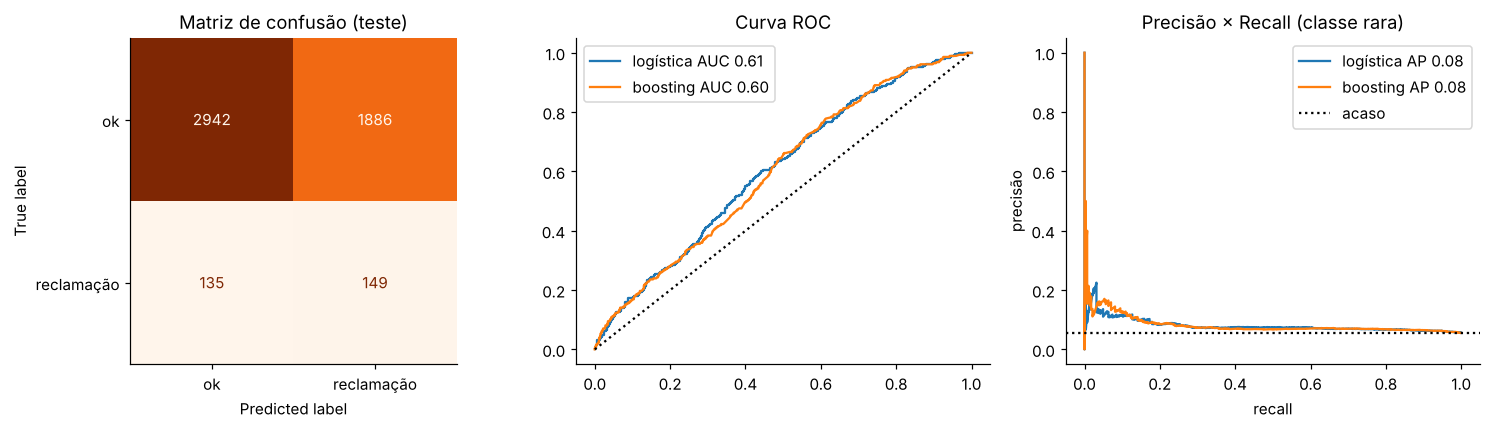

[[2942 1886]
 [ 135  149]]


In [6]:
# limiar que captura ~60% das reclamações (recall alvo), escolhido no treino
ptr=mod.predict_proba(tr[num2+cat2])[:,1]; thr=np.quantile(ptr[tr.y==1],.40); yh=(p2>=thr).astype(int)
met2=dict(acuracia=accuracy_score(te.y,yh),precisao=precision_score(te.y,yh),recall=recall_score(te.y,yh),f1=f1_score(te.y,yh)); print({k:round(v,3) for k,v in met2.items()})
fig,ax=plt.subplots(1,3,figsize=(14,4)); ConfusionMatrixDisplay(confusion_matrix(te.y,yh),display_labels=["ok","reclamação"]).plot(ax=ax[0],colorbar=False,cmap="Oranges"); ax[0].set_title("Matriz de confusão (teste)")
for n,pp in {"logística":p2,"boosting":pg}.items():
    fpr,tpr,_=roc_curve(te.y,pp); ax[1].plot(fpr,tpr,label=f"{n} AUC {roc_auc_score(te.y,pp):.2f}"); pr,rcl,_=precision_recall_curve(te.y,pp); ax[2].plot(rcl,pr,label=f"{n} AP {average_precision_score(te.y,pp):.2f}")
ax[1].plot([0,1],[0,1],"k:"); ax[1].set_title("Curva ROC"); ax[1].legend(); ax[2].axhline(te.y.mean(),c="k",ls=":",label="acaso"); ax[2].set_title("Precisão × Recall (classe rara)"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precisão"); ax[2].legend(); plt.tight_layout(); plt.savefig("../out/fig/clf2.png"); plt.show(); print(confusion_matrix(te.y,yh))

In [7]:
co=pd.Series(mod[-1].coef_[0],index=num2+list(mod[0].named_transformers_["c"].get_feature_names_out(cat2))).sort_values(); display(co.round(2).to_frame("coeficiente (padronizado)")); print("reclamação (%) com envio no prazo vs atrasado:",(te.groupby("atrasado").y.mean()*100).round(1).to_dict())

,coeficiente (padronizado)
categoria_principal_Acessórios,-0.86
categoria_principal_Moda praia,-0.39
canal_TikTok Shop,-0.14
categoria_principal_Blusas,-0.13
canal_Nuvemshop,-0.13
categoria_principal_Saias,-0.12
espera_envio_h,-0.08
omni,-0.08
qtd_itens,-0.06
canal_Shopee,-0.01


reclamação (%) com envio no prazo vs atrasado: {0: 5.3, 1: 8.2}


**Leitura.** Com classe rara, a **precisão média (AP)** é a medida certa: compare com a linha do acaso (a taxa de reclamação, 5,6%). O modelo fica acima do acaso (AP ≈ 0,08; AUC ≈ 0,60), porém **é um modelo fraco**: com o limiar escolhido, a precisão é 0,07 (de cada 100 pedidos sinalizados, ~7 viram reclamação, contra ~5,6 ao acaso) e o recall 0,53. Reclamação depende muito de fatores que a Atria não observa (qualidade real da peça, expectativa do cliente). Conclusão honesta: **não usar para decidir nada automaticamente**; no máximo como apoio para conferir pedidos atrasados e de categorias de maior devolução. Entre os pedidos do teste, a taxa de reclamação é 8,2% quando o envio atrasou contra 5,3% no prazo; o atraso é o fator de processo que o lojista controla. O restante do poder de separação vem da categoria (tabela de coeficientes acima).

## Limitações e honestidade
- Dados simulados: a relação “atraso → reclamação” foi plantada, então o modelo a reencontra; em dados reais o resultado seria um teste, não uma garantia.
- Descartamos um terceiro modelo (“prever a prioridade do alerta”) porque a prioridade é calculada por regra a partir das mesmas variáveis: o modelo só reaprenderia a regra (circularidade).